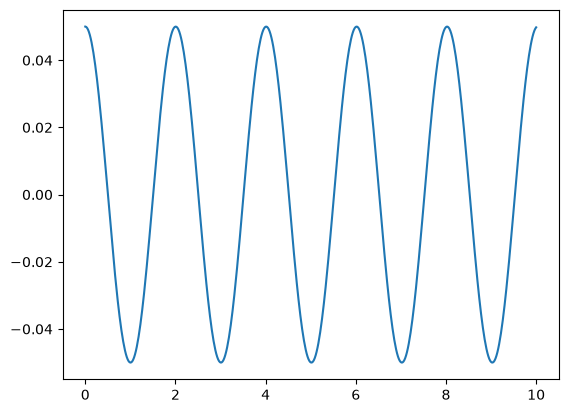

In [32]:
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 10, 500)
plt.plot(t, 0.05 * np.cos(np.sqrt(9.81) * t))
plt.show()

In [33]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
import wahadlo as pd_sim

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
pd_sim.dynamics(np.array([0.1, 0.0]))

array([ 0.        , -0.97936582])

In [35]:
pd_sim.euler_step(pd_sim.dynamics, np.array([0.1, 0.0]), 0.01)


array([ 0.1       , -0.00979366])

In [36]:
xs = pd_sim.simulate(pd_sim.euler_step, pd_sim.dynamics, np.array([0.1, 0.0]), 0.01, 3000)
xs.shape

(3001, 2)

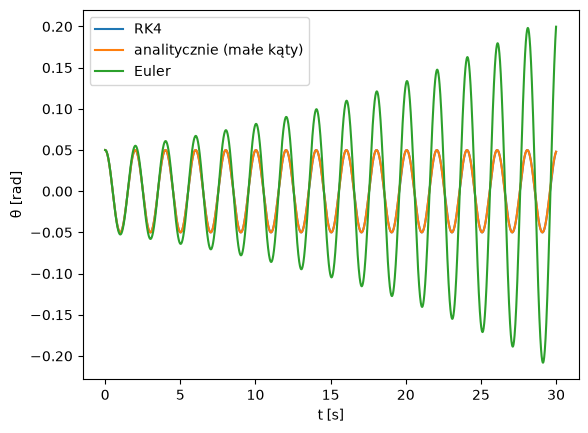

In [37]:
dt, n = 0.01, 3000
t = np.arange(n + 1) * dt
x0 = np.array([0.05, 0.0])

xs_e = pd_sim.simulate(pd_sim.euler_step, pd_sim.dynamics, x0, dt, n)
theta_exact = x0[0] * np.cos(np.sqrt(pd_sim.G) * t)
xs_rk = pd_sim.simulate(pd_sim.rk4_step, pd_sim.dynamics, x0, dt, n)
plt.plot(t, xs_rk[:, 0], label="RK4")

plt.plot(t, theta_exact, label="analitycznie (małe kąty)")
plt.plot(t, xs_e[:, 0], label="Euler")
plt.xlabel("t [s]"); plt.ylabel("θ [rad]"); plt.legend(); plt.show()

In [38]:
pd_sim.rk4_step(pd_sim.dynamics, np.array([0.1, 0.0]), 0.01)

array([ 0.09995104, -0.00979206])

In [39]:
E = pd_sim.energy(xs_rk)
E.shape, E[0]

((3001,), np.float64(-9.79774005447462))

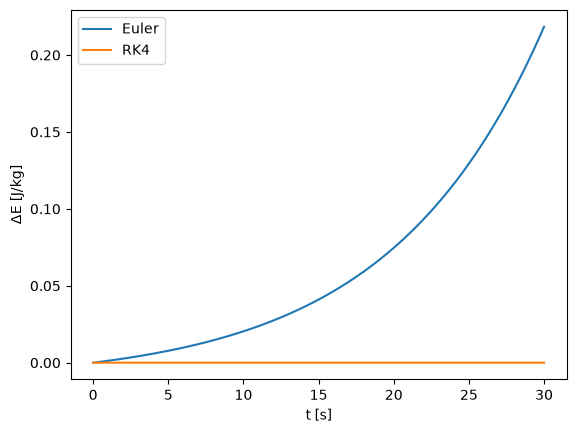

In [40]:
E_e = pd_sim.energy(xs_e)
E_rk = pd_sim.energy(xs_rk)

plt.plot(t, E_e - E_e[0], label="Euler")
plt.plot(t, E_rk - E_rk[0], label="RK4")
plt.xlabel("t [s]"); plt.ylabel("ΔE [J/kg]"); plt.legend(); plt.show()

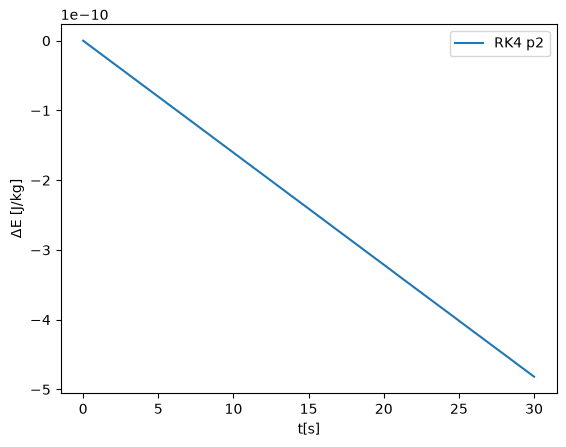

In [41]:
plt.plot(t, E_rk - E_rk[0], label="RK4 p2")
plt.xlabel("t[s]")
plt.ylabel("ΔE [J/kg]")
plt.legend()
plt.show()

In [42]:
def run(step_fn, x0, dt, T=30.0, f=pd_sim.dynamics):
    n = int(round(T/dt))
    t = np.arange(n+1) * dt
    xs = pd_sim.simulate(step_fn, f, np.array(x0), dt, n)
    return t, xs

    

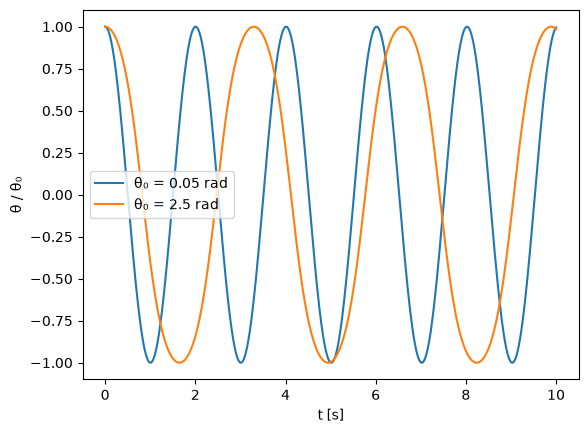

In [43]:
t, xs_small = run(pd_sim.rk4_step, [0.05, 0.0], 0.01, T=10)
t, xs_big = run(pd_sim.rk4_step, [2.5, 0.0], 0.01, T=10)

plt.plot(t, xs_small[:, 0] / 0.05, label="θ₀ = 0.05 rad")
plt.plot(t, xs_big[:, 0] / 2.5, label="θ₀ = 2.5 rad")
plt.xlabel("t [s]"); plt.ylabel("θ / θ₀"); plt.legend(); plt.show()

In [44]:
def measure_period(t, theta):
    idx = np.where((theta[:-1] < 0) & (theta[1:] >= 0))[0]
    return np.mean(np.diff(t[idx]))

measure_period(t, xs_small[:, 0]), measure_period(t, xs_big[:, 0])

(np.float64(2.0075), np.float64(3.295))

In [45]:
from scipy.special import ellipk
theta0 = 2.5
4 * ellipk(np.sin(theta0 / 2)**2) / np.sqrt(pd_sim.G)

np.float64(3.2959322465161165)

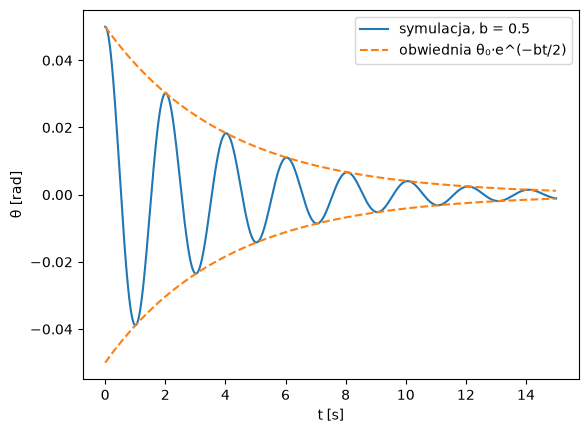

In [46]:
damped = lambda x: pd_sim.dynamics(x, b=0.5)
t, xs_d = run(pd_sim.rk4_step, [0.05, 0.0], 0.01, T=15, f=damped)

envelope = 0.05 * np.exp(-0.5 * 0.5 * t)   # θ₀ · e^(−b·t/2)

plt.plot(t, xs_d[:, 0], label="symulacja, b = 0.5")
plt.plot(t, envelope, "--", label="obwiednia θ₀·e^(−bt/2)")
plt.plot(t, -envelope, "--", color="C1")
plt.xlabel("t [s]"); plt.ylabel("θ [rad]"); plt.legend(); plt.show()

In [47]:
x0 = [0.05, 0.0]
t_rk, xs_rk_big = run(pd_sim.rk4_step, x0, 0.1)
t_eu, xs_eu_small = run(pd_sim.euler_step, x0, 0.001)

for name, xs in [("RK4, dt=0.1", xs_rk_big), ("Euler, dt=0.001", xs_eu_small)]:
    E = pd_sim.energy(xs)
    print(f"{name}: ΔE po 30 s = {E[-1] - E[0]:.2e} J/kg")

RK4, dt=0.1: ΔE po 30 s = -4.75e-05 J/kg
Euler, dt=0.001: ΔE po 30 s = 4.19e-03 J/kg


In [48]:
%timeit run(pd_sim.rk4_step, x0, 0.1)
%timeit run(pd_sim.euler_step, x0, 0.001)

2.74 ms ± 67.8 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
52.4 ms ± 827 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
